In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras import models,layers
from tensorflow.keras.layers import Input,Dense,RepeatVector,LSTM,TimeDistributed
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix

In [36]:
df = pd.read_csv("NASA TurboFan Engine.csv")
print(df.head())
print(df.shape)

   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     39.06   23.4

In [37]:
x = df.drop(["unit","cycle","RUL","Fault_Label"],axis=1)
y = df["Fault_Label"]

In [38]:
x_train,x_test, y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)
x_train = x_train[y_train == 0]

In [39]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [40]:
x_train = x_train.reshape(x_train.shape[0],1,x_train.shape[1])
x_test = x_test.reshape(x_test.shape[0],1,x_test.shape[1])

In [44]:
model = Sequential([
    Input(shape=(1,x_train.shape[2])),
    LSTM(32,activation="relu"),
    RepeatVector(1),
    LSTM(32,activation="relu",return_sequences=True),
    TimeDistributed(Dense(x_train.shape[2]))
])

model.compile(
    optimizer = "adam",
    loss="mse"
)
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                        │ (None, 32)                  │           7,296 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_4 (RepeatVector)       │ (None, 1, 32)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_9 (LSTM)                        │ (None, 1, 32)               │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_4 (TimeDistributed) │ (None, 1, 24)               │             792 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,408 (64.09 KB)

 Trainable params: 16,408 (64.09 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
history = model.fit(
    x_train,x_train,
    epochs=10,
    validation_split=0.1,
    batch_size=32
)


Epoch 1/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0334 - val_loss: 0.0084
Epoch 2/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0058 - val_loss: 0.0041
Epoch 3/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0034 - val_loss: 0.0028
Epoch 4/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 5/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0017
Epoch 6/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 7/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0011 - val_loss: 8.8944e-04
Epoch 8/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 7.7567e-04 - val_loss: 6.1399e-04
Epoch 9/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 4.6207e-04 - val_loss: 3.2843e-04
Epoch 10/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 2.7643e-04 - val_loss: 1.9384e-04


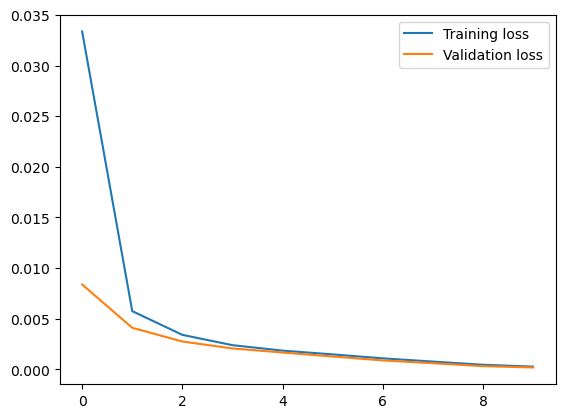

In [49]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("epoch")
plt.ylabel=("loss")
plt.legend()
plt.show()

In [50]:
train_pred = model.predict(x_train)
train_error = np.mean(np.square(train_pred - x_train),axis=(1,2))
threshold = np.mean(train_error) + 3*np.std(train_error)
print("Threshold:",threshold)

439/439 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step    
Threshold: 0.0007806907220776553


In [51]:
test_pred = model.predict(x_test)
test_error = np.mean(np.square(test_pred-x_test),axis=(1,2))
y_pred = (test_error>threshold).astype(int)
print("Detected Faults:",np.sum(y_pred))

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Detected Faults: 152


In [52]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[3444   63]
 [ 531   89]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92      3507
           1       0.59      0.14      0.23       620

    accuracy                           0.86      4127
   macro avg       0.73      0.56      0.58      4127
weighted avg       0.82      0.86      0.82      4127



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras import models,layers
from tensorflow.keras.layers import Input,Dense,RepeatVector,LSTM,TimeDistributed
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix


df = pd.read_csv("NASA TurboFan Engine.csv")
print(df.head())
print(df.shape)


x = df.drop(["unit","cycle","RUL","Fault_Label"],axis=1)
y = df["Fault_Label"]

x_train,x_test, y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)
x_train = x_train[y_train == 0]

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


x_train = x_train.reshape(x_train.shape[0],1,x_train.shape[1])
x_test = x_test.reshape(x_test.shape[0],1,x_test.shape[1])


model = Sequential([
    Input(shape=(1,x_train.shape[2])),
    LSTM(32,activation="relu"),
    RepeatVector(1),
    LSTM(32,activation="relu",return_sequences=True),
    TimeDistributed(Dense(x_train.shape[2]))
])

model.compile(
    optimizer = "adam",
    loss="mse"
)
model.summary()

history = model.fit(
    x_train,x_train,
    epochs=10,
    validation_split=0.1,
    batch_size=32
)


plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("epoch")
plt.ylabel=("loss")
plt.legend()
plt.show()



train_pred = model.predict(x_train)
train_error = np.mean(np.square(train_pred - x_train),axis=(1,2))
threshold = np.mean(train_error) + 3*np.std(train_error)
print("Threshold:",threshold)

test_pred = model.predict(x_test)
test_error = np.mean(np.square(test_pred-x_test),axis=(1,2))
y_pred = (test_error>threshold).astype(int)
print("Detected Faults:",np.sum(y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))